# Bifurcations

**Seong Cho** · ACME Volume 4, Lab 6

**Lab objective:** trace how the equilibria of a parameter-dependent ODE change as the parameter varies, using the natural embedding algorithm to draw bifurcation diagrams, and study hysteresis in a model of spruce budworm population dynamics.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

Any ordinary differential equation can be written as a first order system

$$\dot{x} = F(x), \qquad \dot{x} := \frac{d}{dt}x(t). \tag{6.1}$$

A *phase portrait* describes the solutions of (6.1) for different initial conditions; the first step in drawing one is to find the equilibrium solutions (the zeros of $F$) and determine their stability.

Often the model depends on a parameter (or parameters) $\lambda$,

$$\dot{x} = F(x, \lambda), \tag{6.2}$$

and as $\lambda$ varies the equilibria and other geometric features of (6.2) may suddenly change. A value of $\lambda$ where the phase portrait changes is a *bifurcation point*, the study of how these changes occur is *bifurcation theory*, and the parameter values and corresponding equilibria are graphed together in a *bifurcation diagram*.

For example,

$$\dot{x} = x^2 + \lambda \tag{6.3}$$

has no equilibria for $\lambda > 0$. At $\lambda = 0$ the equilibrium $x = 0$ appears, and for $\lambda < 0$ it splits into two equilibria $x = \pm\sqrt{-\lambda}$: a *saddle-node bifurcation* at $\lambda = 0$.

## Natural Embedding

Given a zero $F(x_0, \lambda_0) = 0$, *natural embedding* finds zeros $(x, \lambda)$ for nearby values of $\lambda$: step to $\lambda_1 = \lambda_0 + \Delta\lambda$ and use Newton's method, started from $x_0$, to find $x_1$ with $F(x_1, \lambda_1) = 0$, and repeat. This works well except near a bifurcation point $\lambda^*$, and it needs a good initial guess for $x_0$ to get started. The spec's implementation, used to trace the two curves of the bifurcation diagram of (6.3):

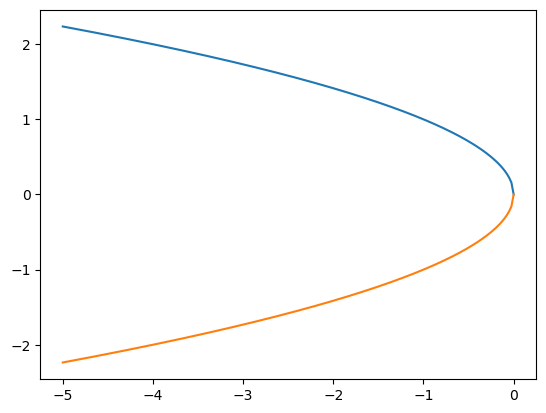

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

def EmbeddingAlg(param_list, guess, F):
    """Performs the natural embedding algorithm for the first-order 
    system of differential equations given by F.
        Parameters
        ----------

    """
    X = []
    for param in param_list:
        try:
            # Solve for x_value making F(x_value, param) = 0.
            x_value = newton(F, guess, fprime=None, args=(param,), tol=1E-7, maxiter=50)
            # Record the solution and update guess for the next iteration.
            X.append(x_value)
            guess = x_value
        except RuntimeError:
            # If Newton's method fails, return a truncated list of parameters
            # with the corresponding x values.
            return param_list[:len(X)], X
    # Return the list of parameters and the corresponding x values.
    return param_list, X

def F(x, lmbda):
    return x**2 + lmbda
# Top curve shown in the bifurcation diagram
C1, X1 = EmbeddingAlg(np.linspace(-5, 0, 200), np.sqrt(5), F)
# The bottom curve
C2, X2 = EmbeddingAlg(np.linspace(-5, 0, 200), -np.sqrt(5), F)

plt.plot(C1, X1)
plt.plot(C2, X2)

## Problem 1: A pitchfork bifurcation

> **Problem 1.** Use the natural embedding algorithm to create a bifurcation diagram for the differential equation
>
> $$\dot{x} = \lambda x - x^3.$$
>
> This type of bifurcation is called a pitchfork bifurcation (you should see a pitchfork in your diagram).

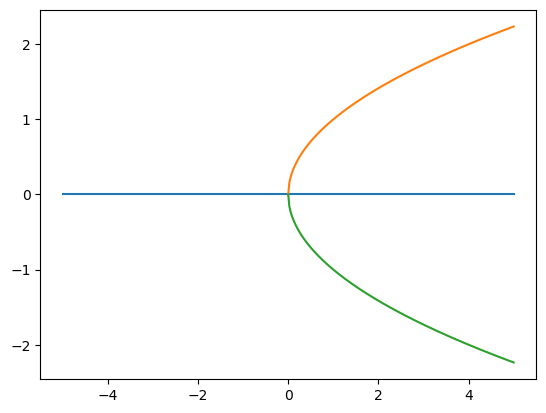

In [2]:
def F(x, lmbda):
    return x*lmbda - x**3
# Y=0 line
C1, X1 = EmbeddingAlg(np.linspace(-5, 5, 200), 0, F)
# Top Curve
C2, X2 = EmbeddingAlg(np.linspace(5, 0, 200), 2, F)
# Bottom Curve
C3, X3 = EmbeddingAlg(np.linspace(5, 0, 200), -2, F)

plt.plot(C1, X1)
plt.plot(C2, X2)
plt.plot(C3, X3)
plt.show()

## Problem 2: An imperfect pitchfork

> **Problem 2.** Create bifurcation diagrams for the differential equation
>
> $$\dot{x} = \eta + \lambda x - x^3$$
>
> where $\eta = -1, -.2, .2$ and $1$. Notice that when $\eta = 0$ you can see the pitchfork bifurcation of the previous problem. There should be four different images, one for each value of $\eta$. Each image will be built of 3 pieces.

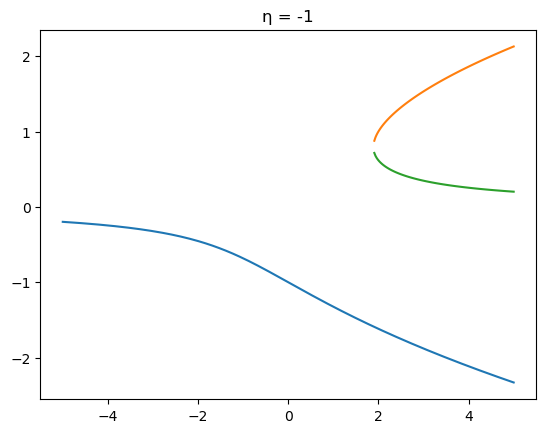

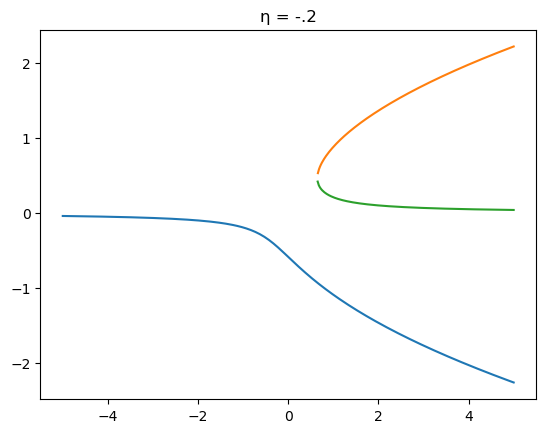

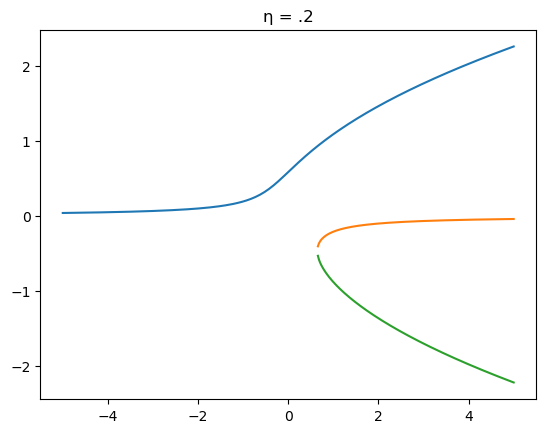

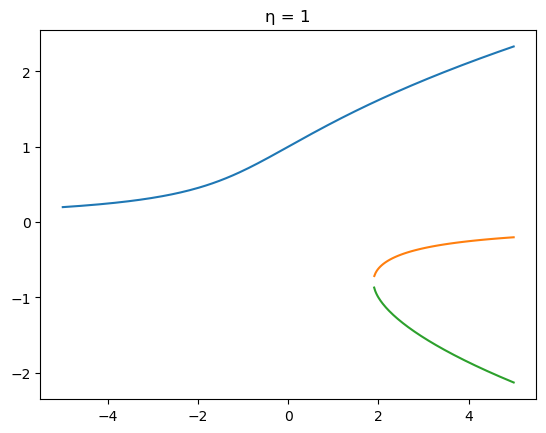

In [3]:
def F(x, lmbda):
    return eta + x*lmbda - x**3
eta = -1
C1, X1 = EmbeddingAlg(np.linspace(-5, 5, 200), 0, F)
C2, X2 = EmbeddingAlg(np.linspace(5, 0, 200), 2, F)
C3, X3 = EmbeddingAlg(np.linspace(5, 0, 200), 0, F)

plt.plot(C1, X1)
plt.plot(C2, X2)
plt.plot(C3, X3)
plt.title("η = -1")
plt.show()

def F(x, lmbda):
    return eta + x*lmbda - x**3
eta = -.2
C1, X1 = EmbeddingAlg(np.linspace(-5, 5, 200), 0, F)
C2, X2 = EmbeddingAlg(np.linspace(5, 0.5, 200), 2, F)
C3, X3 = EmbeddingAlg(np.linspace(5, 0, 200), -1, F)

plt.plot(C1, X1)
plt.plot(C2, X2)
plt.plot(C3, X3)
plt.title("η = -.2")
plt.show()

def F(x, lmbda):
    return eta + x*lmbda - x**3
eta = .2
C1, X1 = EmbeddingAlg(np.linspace(-5, 5, 200), 0, F)
C2, X2 = EmbeddingAlg(np.linspace(5, 0.5, 200), 1, F)
C3, X3 = EmbeddingAlg(np.linspace(5, 0.5, 200), -2, F)

plt.plot(C1, X1)
plt.plot(C2, X2)
plt.plot(C3, X3)
plt.title("η = .2")
plt.show()

def F(x, lmbda):
    return eta + x*lmbda - x**3
eta = 1   # Changed: was .2 again, so the "η = 1" plot repeated η = .2
C1, X1 = EmbeddingAlg(np.linspace(-5, 5, 200), 0, F)
C2, X2 = EmbeddingAlg(np.linspace(5, 0, 200), 0, F)
C3, X3 = EmbeddingAlg(np.linspace(5, 0.3, 200), -2, F)

plt.plot(C1, X1)
plt.plot(C2, X2)
plt.plot(C3, X3)
plt.title("η = 1")
plt.show()

## Hysteresis

The ODE

$$x' = \lambda + x - x^3$$

has a bifurcation diagram containing a *hysteresis loop*: when $\lambda$ moves beyond a bifurcation point, the equilibrium jumps suddenly to the other stable branch, and the system cannot reach its previous equilibrium by simply rewinding the parameter slightly.

### Budworm population dynamics

In eastern Canada, an outbreak of the spruce budworm can destroy most of the trees in a forest of balsam fir in about 4 years. The model (Ludwig et al., 1978; described well in Strogatz's *Nonlinear Dynamics and Chaos*) is

$$\dot{N} = RN\left(1 - \frac{N}{K}\right) - p(N), \tag{6.4}$$

where $N(t)$ is the budworm population, $R$ its growth rate, $K$ the carrying capacity of the environment (think of the amount of food available), and $p(N) = \frac{BN^2}{A^2 + N^2}$ the death rate due to predators (birds). Nondimensionalizing with $x = N/A$, $\tau = Bt/A$, $r = RA/B$ and $k = K/A$ gives

$$\frac{dx}{d\tau} = rx\left(1 - \frac{x}{k}\right) - \frac{x^2}{1 + x^2}. \tag{6.5}$$

$x = 0$ is always an equilibrium; the others solve $r(1 - x/k) = x/(1 + x^2)$, the crossings of a line and a fixed curve. With $r = .56$, as $k$ increases the line $y = r(1 - x/k)$ gets more shallow and the number of nonzero equilibria goes from one to three and back to one.

In the bifurcation diagram, the lower stable branch is the *refuge* level of the budworm population and the upper stable branch the *outbreak* level. Once the population reaches outbreak level, the available food (foliage of the balsam fir trees) must be reduced drastically to jump back down to refuge level, so many of the trees die before the population returns to refuge level.

## Problem 3: The budworm bifurcation diagram

> **Problem 3.** Reproduce the bifurcation diagram for the differential equation
>
> $$\frac{dx}{d\tau} = rx(1 - x/k) - \frac{x^2}{1 + x^2}$$
>
> where $r = 0.56$.

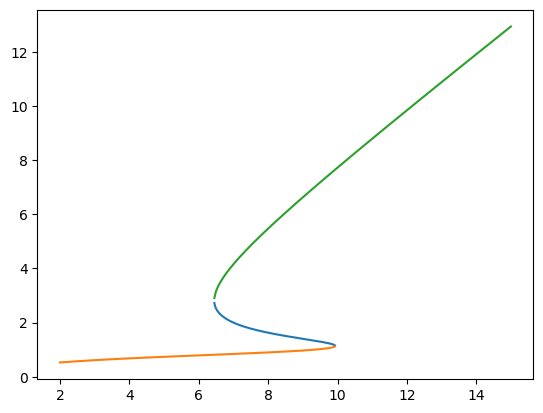

In [4]:
def F(x, k):
    return r*x*(1-x/k) - x**2 / (1+x**2)
r = .56
# Middle Curve
C1, X1 = EmbeddingAlg(np.linspace(6.45, 10, 200), 2, F)
# Bottom Curve
C2, X2 = EmbeddingAlg(np.linspace(2, 10, 200), 1.5, F)
# Top Curve
C3, X3 = EmbeddingAlg(np.linspace(15, 6.45, 200), 10, F)


plt.plot(C1, X1)
plt.plot(C2, X2)
plt.plot(C3, X3)

plt.show()